1. Initialization: Initialize the weights of the convolutional kernel and any other layers randomly.

2. Forward Pass:
    - Input a batch of training samples into the network.
    - Perform the convolution operation.
    - Apply activation functions (e.g., ReLU) after the convolution.
    - Perform the max-pooling operation.
    - Flatten the output of the max-pooling layer.
    - Pass the flattened output through one or more fully connected layers.
    - Apply an activation function (e.g., softmax for classification) to get the final output.

3. Compute Loss: Compare the network's output with the true labels using a loss function (e.g., cross-entropy loss for classification).

4. Backward Pass (Backpropagation):
    - Calculate the gradient of the loss function with respect to the weights using backpropagation.
    - Update the weights using an optimization algorithm (e.g., SGD) to minimize the loss function.
    - Optionally, use techniques like momentum or adaptive learning rates (e.g., Adam) for faster convergence.

5. Repeat: Repeat steps 2-4 for a specified number of epochs or until convergence.

In [2]:
!git clone https://github.com/greydanus/mnist1d

Cloning into 'mnist1d'...
remote: Enumerating objects: 432, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 432 (delta 45), reused 44 (delta 44), pack-reused 381
Receiving objects: 100% (432/432), 12.25 MiB | 2.44 MiB/s, done.
Resolving deltas: 100% (198/198), done.


In [ ]:
!pip install git+https://github.com/greydanus/mnist1d.git

In [1]:
import numpy as np
import os
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import matplotlib.pyplot as plt
import mnist1d
import random

In [2]:
args = mnist1d.data.get_dataset_args()
data = mnist1d.data.get_dataset(args, path='./mnist1d_data.pkl', download=False, regenerate=False)

# The training and test input and outputs are in
# data['x'], data['y'], data['x_test'], and data['y_test']
print("Examples in training set: {}".format(len(data['y'])))
print("Examples in test set: {}".format(len(data['y_test'])))
print("Length of each example: {}".format(data['x'].shape[-1]))

Successfully loaded data from ./mnist1d_data.pkl
Examples in training set: 4000
Examples in test set: 1000
Length of each example: 40


In [3]:
# Load in the data
train_data_x = data['x'].transpose()
train_data_y = data['y']
val_data_x = data['x_test'].transpose()
val_data_y = data['y_test']
# Print out sizes
print("Train data: %d examples (columns), each of which has %d dimensions (rows)"%((train_data_x.shape[1],train_data_x.shape[0])))
print("Validation data: %d examples (columns), each of which has %d dimensions (rows)"%((val_data_x.shape[1],val_data_x.shape[0])))


Train data: 4000 examples (columns), each of which has 40 dimensions (rows)
Validation data: 1000 examples (columns), each of which has 40 dimensions (rows)


In [4]:
# There are 40 input dimensions and 10 output dimensions for this data
# The inputs correspond to the 40 offsets in the MNIST1D template.
D_i = 40
# The outputs correspond to the 10 digits
D_o = 10


# TODO Create a model with the following layers
# 1. Convolutional layer, (input=length 40 and 1 channel, kernel size 3, stride 2, padding="valid", 15 output channels )
# 2. ReLU
# 3. Convolutional layer, (input=length 19 and 15 channels, kernel size 3, stride 2, padding="valid", 15 output channels )
# 4. ReLU
# 5. Convolutional layer, (input=length 9 and 15 channels, kernel size 3, stride 2, padding="valid", 15 output channels)
# 6. ReLU
# 7. Flatten (converts 4x15) to length 60
# 8. Linear layer (input size = 60, output size = 10)
# References:
# https://pytorch.org/docs/1.13/generated/torch.nn.Conv1d.html?highlight=conv1d#torch.nn.Conv1d
# https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html
# https://pytorch.org/docs/1.13/generated/torch.nn.Linear.html?highlight=linear#torch.nn.Linear

# NOTE THAT THE CONVOLUTIONAL LAYERS NEED TO TAKE THE NUMBER OF INPUT CHANNELS AS A PARAMETER
# AND NOT THE INPUT SIZE.

model = nn.Sequential(
    nn.Conv1d(1, 15, kernel_size=3, stride=2, padding=0),
    nn.ReLU(),
    nn.Conv1d(15, 15, kernel_size=3, stride=2, padding=0),
    nn.ReLU(),
    nn.Conv1d(15, 15, kernel_size=3, stride=2, padding=0),
    nn.ReLU(),
    nn.Flatten(),
    nn.Linear(60, 10),
)

In [5]:
# He initialization of weights
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)
     

Epoch     0, train loss 2.212055, train error 84.38,  val loss 2.229543, percent error 84.40
Epoch     1, train loss 1.933502, train error 74.97,  val loss 1.957919, percent error 76.00
Epoch     2, train loss 1.619972, train error 67.15,  val loss 1.629147, percent error 67.80
Epoch     3, train loss 1.390745, train error 57.92,  val loss 1.403360, percent error 59.50
Epoch     4, train loss 1.265414, train error 52.72,  val loss 1.298400, percent error 55.90
Epoch     5, train loss 1.194111, train error 50.03,  val loss 1.228245, percent error 51.60
Epoch     6, train loss 1.129068, train error 44.75,  val loss 1.141266, percent error 45.80
Epoch     7, train loss 0.974091, train error 39.33,  val loss 0.998843, percent error 40.40
Epoch     8, train loss 0.884814, train error 34.43,  val loss 0.927178, percent error 37.10
Epoch     9, train loss 0.804774, train error 31.35,  val loss 0.845665, percent error 33.60
Epoch    10, train loss 0.726353, train error 27.75,  val loss 0.77362

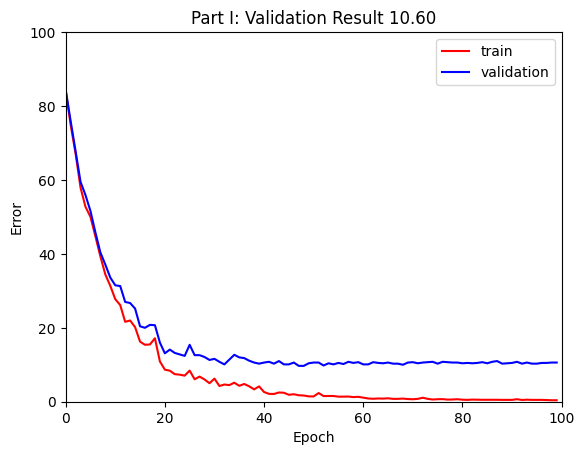

In [6]:
# choose cross entropy loss function (equation 5.24 in the loss notes)
loss_function = nn.CrossEntropyLoss()
# construct SGD optimizer and initialize learning rate and momentum
optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)
# object that decreases learning rate by half every 20 epochs
scheduler = StepLR(optimizer, step_size=20, gamma=0.5)
# create 100 dummy data points and store in data loader class
x_train = torch.tensor(train_data_x.transpose().astype('float32'))
y_train = torch.tensor(train_data_y.astype('long')).long()
x_val= torch.tensor(val_data_x.transpose().astype('float32'))
y_val = torch.tensor(val_data_y.astype('long')).long()

# load the data into a class that creates the batches
data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=100, shuffle=True, worker_init_fn=np.random.seed(1))

# Initialize model weights
model.apply(weights_init)

# loop over the dataset n_epoch times
n_epoch = 100
# store the loss and the % correct at each epoch
losses_train = np.zeros((n_epoch))
errors_train = np.zeros((n_epoch))
losses_val = np.zeros((n_epoch))
errors_val = np.zeros((n_epoch))

for epoch in range(n_epoch):
    # loop over batches
    for i, data in enumerate(data_loader):
        # retrieve inputs and labels for this batch
        x_batch, y_batch = data
        # zero the parameter gradients
        optimizer.zero_grad()
        # forward pass -- calculate model output
        pred = model(x_batch[:, None, :])
        # compute the loss
        loss = loss_function(pred, y_batch)
        # backward pass
        loss.backward()
        # SGD update
        optimizer.step()

    # Run whole dataset to get statistics -- normally wouldn't do this
    pred_train = model(x_train[:,None,:])
    pred_val = model(x_val[:,None,:])
    _, predicted_train_class = torch.max(pred_train.data, 1)
    _, predicted_val_class = torch.max(pred_val.data, 1)
    errors_train[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
    errors_val[epoch] = 100 - 100 * (predicted_val_class == y_val).float().sum() / len(y_val)
    losses_train[epoch] = loss_function(pred_train, y_train).item()
    losses_val[epoch] = loss_function(pred_val, y_val).item()
    print(f'Epoch {epoch:5d}, train loss {losses_train[epoch]:.6f}, train error {errors_train[epoch]:3.2f},  val loss {losses_val[epoch]:.6f}, percent error {errors_val[epoch]:3.2f}')

    # tell scheduler to consider updating learning rate
    scheduler.step()

# Plot the results
fig, ax = plt.subplots()
ax.plot(errors_train,'r-',label='train')
ax.plot(errors_val,'b-',label='validation')
ax.set_ylim(0,100); ax.set_xlim(0,n_epoch)
ax.set_xlabel('Epoch'); ax.set_ylabel('Error')
ax.set_title('Part I: Validation Result %3.2f'%(errors_val[-1]))
ax.legend()
plt.show()